# Correlações
```
Tema: Impacto da IA e das redes sociais na saúde e no desempenho dos estudantes
```
**Pergunta:** o uso de redes sociais e de IA está associado à saúde (sono, bem-estar) e ao desempenho (frequência, atenção, risco acadêmico, nota)?

Usamos **Pearson** (relação linear) e **Spearman** (relação monotônica, robusta a outliers).

---

In [14]:
import time
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ARQUIVO = "estudantes.parquet"

inicial = pl.scan_parquet(ARQUIVO)
esquema = inicial.collect_schema()
colunas = esquema.names()
numericas = [c for c, t in esquema.items() if t.is_numeric()]

# Métricas de saúde e desempenho usadas nos resumos
METRICAS = list(dict.fromkeys(
    c for c in ["horas_redes_sociais", "horas_sono", "pontuacao_vicio_digital", "indice_bem_estar",
                "taxa_frequencia_aulas", "capacidade_atencao_minutos", "pontuacao_risco_academico",]
    if c and c in colunas
))

def perfil(lf, grupo):
    """Resumo por grupo: nº de estudantes + média das métricas do tema."""
    return (
        lf.group_by(grupo)
        .agg([pl.len().alias("estudantes")] +
             [pl.col(c).mean().round(2).alias(f"media_{c}") for c in METRICAS])
        .sort(grupo)
    )


def categorizar(lf):
    """Cria categorias de sono, redes sociais."""
    exprs = [
        pl.when(pl.col("horas_sono") <= 6).then(pl.lit("1-Baixo (≤6h)"))
          .when(pl.col("horas_sono") < 8).then(pl.lit("2-Médio (6-8h)"))
          .otherwise(pl.lit("3-Bom (≥8h)")).alias("categoria_sono"),
        pl.when(pl.col("horas_redes_sociais") < 2).then(pl.lit("1-Baixo (<2h)"))
          .when(pl.col("horas_redes_sociais") < 5).then(pl.lit("2-Moderado (2-5h)"))
          .otherwise(pl.lit("3-Alto (≥5h)")).alias("categoria_redes"),
    ]
    return lf.with_columns(exprs)

In [15]:
preditores = [c for c in ["horas_redes_sociais", "pontuacao_vicio_digital"] if c and c in colunas]
saude = [c for c in ["horas_sono", "indice_bem_estar"] if c in colunas]
desempenho = [c for c in ["taxa_frequencia_aulas", "capacidade_atencao_minutos", "pontuacao_risco_academico"] if c and c in colunas]
alvos = saude + desempenho

todas = list(dict.fromkeys(preditores + alvos))
df = inicial.select(todas).drop_nulls().collect()
print(f"{df.height:,} estudantes | preditores: {preditores}")
print(f"saúde: {saude} | desempenho: {desempenho}")

500,000 estudantes | preditores: ['horas_redes_sociais', 'pontuacao_vicio_digital']
saúde: ['horas_sono', 'indice_bem_estar'] | desempenho: ['taxa_frequencia_aulas', 'capacidade_atencao_minutos', 'pontuacao_risco_academico']


### 1. Matriz de correlação (Pearson)
---

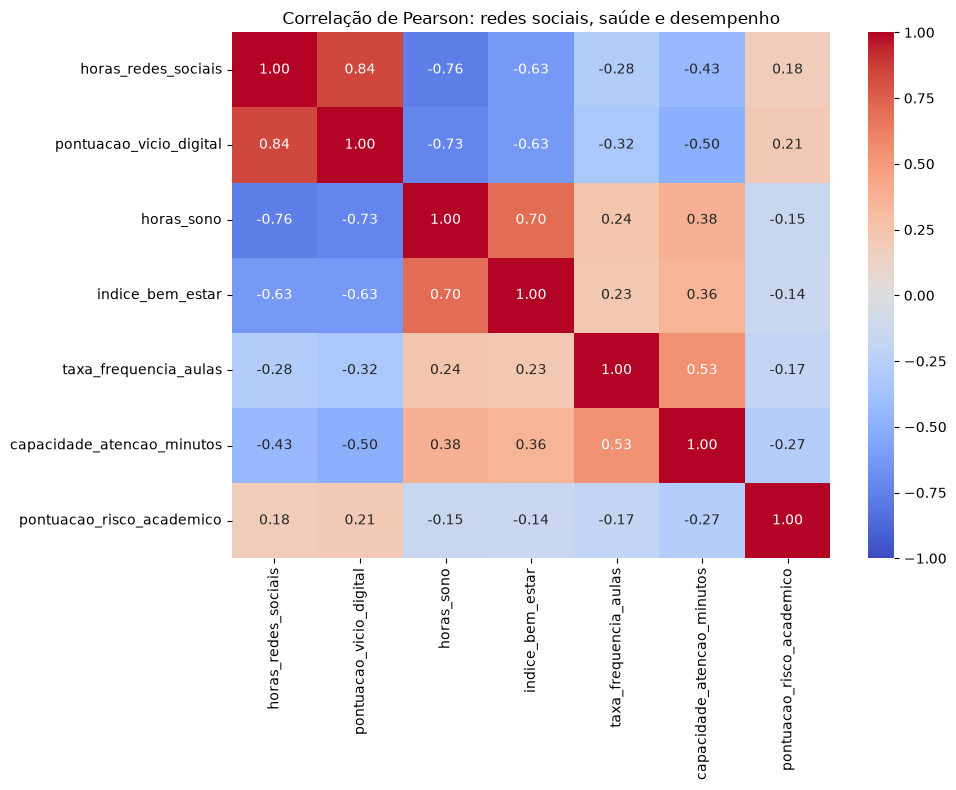

In [16]:
matriz = pd.DataFrame(df.corr().to_numpy(), index=todas, columns=todas)

plt.figure(figsize=(10, 8))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação de Pearson: redes sociais, saúde e desempenho")
plt.tight_layout()
plt.show()

### 2. Preditores x resultados (Pearson e Spearman)
```
|r| < 0,10 desprezível | < 0,30 fraca | < 0,50 moderada | >= 0,50 forte
```
---

In [17]:
def forca(r):
    a = abs(r)
    return "desprezível" if a < 0.1 else "fraca" if a < 0.3 else "moderada" if a < 0.5 else "forte"

linhas = []
for p in preditores:
    for a in alvos:
        if p == a:
            continue
        r = df.select(
            pl.corr(p, a, method="pearson").alias("pearson"),
            pl.corr(p, a, method="spearman").alias("spearman"),
        ).row(0)
        linhas.append({"preditor": p, "alvo": a, "pearson": r[0], "spearman": r[1],
                       "r2": r[0] ** 2, "forca": forca(r[0]),
                       "direcao": "positiva" if r[0] > 0 else "negativa"})

tabela = pl.DataFrame(linhas).with_columns(pl.col("pearson").abs().alias("abs_r")).sort("abs_r", descending=True)
pl.Config.set_tbl_rows(50)
display(tabela.drop("abs_r"))

preditor,alvo,pearson,spearman,r2,forca,direcao
str,str,f64,f64,f64,str,str
"""horas_redes_sociais""","""horas_sono""",-0.761701,-0.750171,0.580188,"""forte""","""negativa"""
"""pontuacao_vicio_digital""","""horas_sono""",-0.727712,-0.714552,0.529565,"""forte""","""negativa"""
"""horas_redes_sociais""","""indice_bem_estar""",-0.632777,-0.621379,0.400407,"""forte""","""negativa"""
"""pontuacao_vicio_digital""","""indice_bem_estar""",-0.629839,-0.617796,0.396697,"""forte""","""negativa"""
"""pontuacao_vicio_digital""","""capacidade_atencao_minutos""",-0.504901,-0.493309,0.254925,"""forte""","""negativa"""
"""horas_redes_sociais""","""capacidade_atencao_minutos""",-0.433372,-0.422437,0.187811,"""moderada""","""negativa"""
"""pontuacao_vicio_digital""","""taxa_frequencia_aulas""",-0.320366,-0.310398,0.102635,"""moderada""","""negativa"""
"""horas_redes_sociais""","""taxa_frequencia_aulas""",-0.276624,-0.267601,0.076521,"""fraca""","""negativa"""
"""pontuacao_vicio_digital""","""pontuacao_risco_academico""",0.2121,0.222239,0.044986,"""fraca""","""positiva"""


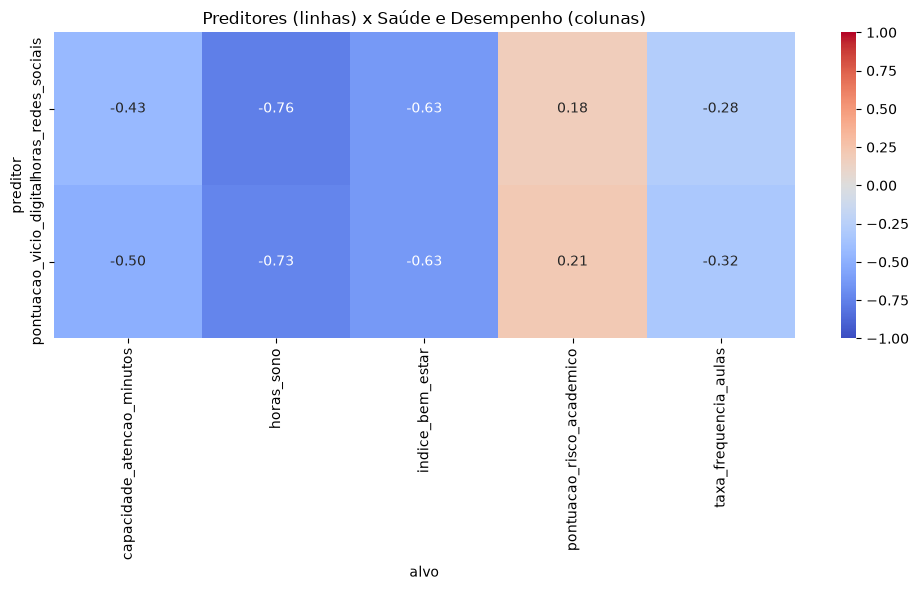

In [18]:
pivot = tabela.to_pandas().pivot(index="preditor", columns="alvo", values="pearson")

plt.figure(figsize=(10, 4 + len(preditores)))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Preditores (linhas) x Saúde e Desempenho (colunas)")
plt.tight_layout()
plt.show()

### 3. Dispersão dos 3 pares mais fortes
```
Amostra de 5.000 estudantes (500 mil pontos ilegíveis) com reta de tendência.
```
---

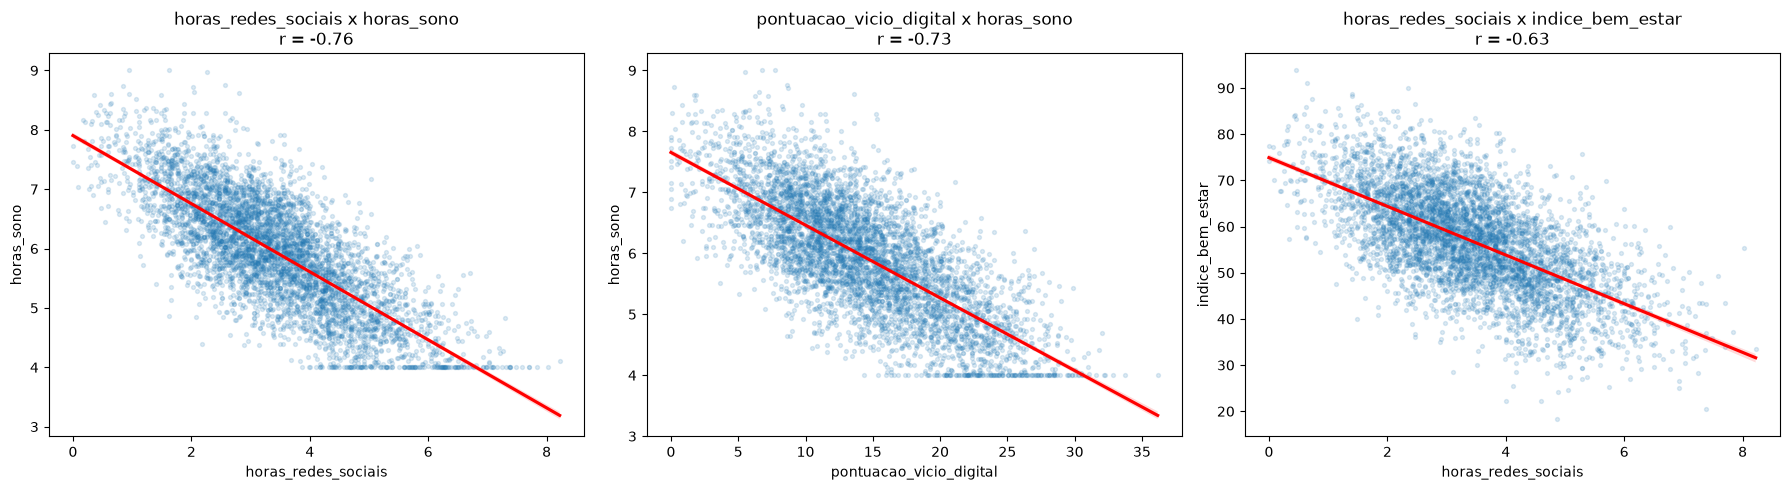

In [19]:
amostra = df.sample(n=min(5000, df.height), seed=42).to_pandas()
top = tabela.head(3).select(["preditor", "alvo", "pearson"]).rows()

fig, axes = plt.subplots(1, len(top), figsize=(6 * len(top), 5), squeeze=False)
for ax, (p, a, r) in zip(axes[0], top):
    sns.regplot(data=amostra, x=p, y=a, ax=ax,
                scatter_kws={"alpha": 0.15, "s": 8}, line_kws={"color": "red"})
    ax.set_title(f"{p} x {a}\nr = {r:.2f}")
plt.tight_layout()
plt.show()

### 4. Médias por nível de uso
```
Visão mais intuitiva: o que acontece com saúde e desempenho conforme o uso aumenta?
```
---

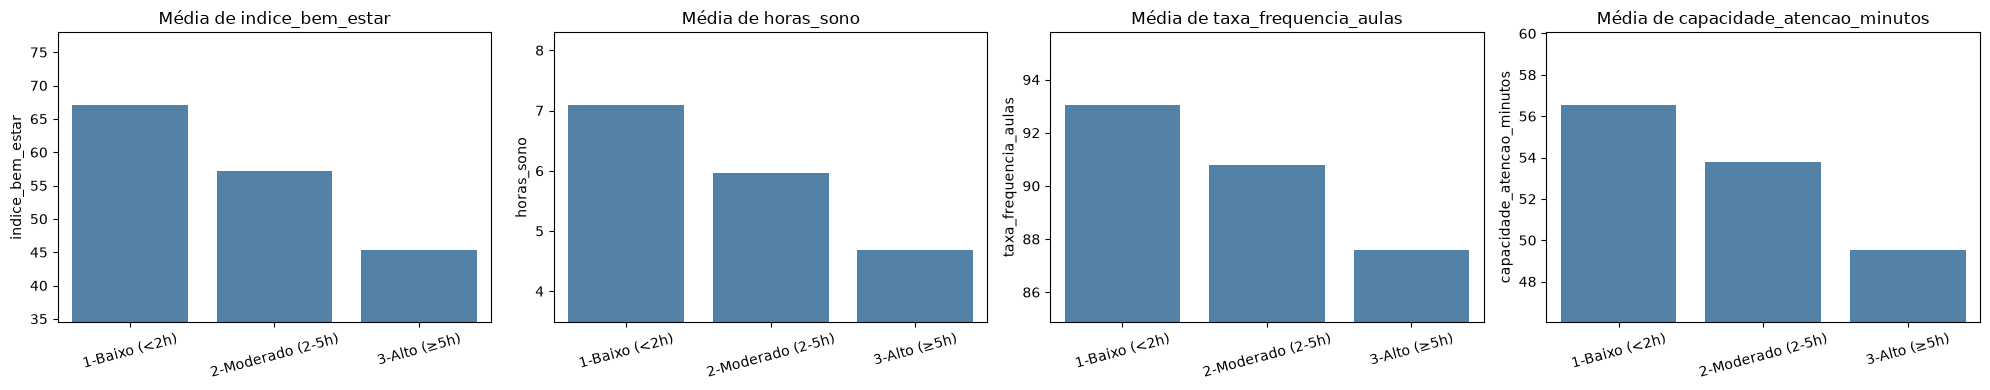

In [21]:
lf_cat = categorizar(inicial)
grupos = ["categoria_redes"]
resumo_alvos = [c for c in ["indice_bem_estar", "horas_sono", "taxa_frequencia_aulas", "capacidade_atencao_minutos"] if c in colunas]

fig, axes = plt.subplots(len(grupos), len(resumo_alvos), figsize=(5 * len(resumo_alvos), 4 * len(grupos)), squeeze=False)
for i, g in enumerate(grupos):
    medias = (
        lf_cat.group_by(g)
        .agg([pl.col(c).mean().alias(c) for c in resumo_alvos])
        .sort(g).collect().to_pandas()
    )
    for j, a in enumerate(resumo_alvos):
        sns.barplot(data=medias, x=g, y=a, ax=axes[i][j], color="steelblue")
        axes[i][j].set_title(f"Média de {a}")
        axes[i][j].set_xlabel("")
        axes[i][j].tick_params(axis="x", rotation=15)
        lo, hi = medias[a].min(), medias[a].max()
        margem = (hi - lo) * 0.5 or 1
        axes[i][j].set_ylim(lo - margem, hi + margem)   # eixo ampliado para mostrar a diferença
plt.tight_layout()
plt.show()

### 5. Conclusões automáticas
---

In [22]:
print("Principais associações (ordenadas por |r|):\n")
for p, a, r, s, f, d in tabela.select(["preditor", "alvo", "pearson", "spearman", "forca", "direcao"]).head(8).rows():
    print(f"- {p} x {a}: Pearson {r:+.3f} | Spearman {s:+.3f} -> correlação {f} {d}")

print("\nSem associação relevante (|r| < 0,10):")
fracas = tabela.filter(pl.col("abs_r") < 0.1).select(["preditor", "alvo"]).rows()
print(", ".join(f"{p} x {a}" for p, a in fracas) or "nenhuma")

Principais associações (ordenadas por |r|):

- horas_redes_sociais x horas_sono: Pearson -0.762 | Spearman -0.750 -> correlação forte negativa
- pontuacao_vicio_digital x horas_sono: Pearson -0.728 | Spearman -0.715 -> correlação forte negativa
- horas_redes_sociais x indice_bem_estar: Pearson -0.633 | Spearman -0.621 -> correlação forte negativa
- pontuacao_vicio_digital x indice_bem_estar: Pearson -0.630 | Spearman -0.618 -> correlação forte negativa
- pontuacao_vicio_digital x capacidade_atencao_minutos: Pearson -0.505 | Spearman -0.493 -> correlação forte negativa
- horas_redes_sociais x capacidade_atencao_minutos: Pearson -0.433 | Spearman -0.422 -> correlação moderada negativa
- pontuacao_vicio_digital x taxa_frequencia_aulas: Pearson -0.320 | Spearman -0.310 -> correlação moderada negativa
- horas_redes_sociais x taxa_frequencia_aulas: Pearson -0.277 | Spearman -0.268 -> correlação fraca negativa

Sem associação relevante (|r| < 0,10):
nenhuma


### Como interpretar (escreva sua conclusão com os números acima)
- **Força:** com 500 mil linhas qualquer correlação é "estatisticamente significativa"; o que importa é o **tamanho** de r.
- **r² :** percentual da variação de um indicador que a outra variável explica linearmente.
- **Vício digital:** a pontuação provavelmente é construída a partir do uso de redes/IA, então a correlação alta com elas é esperada e não é um achado independente.
- **Correlação não é causa:** sono, escolaridade e país podem influenciar tudo ao mesmo tempo. A regressão múltipla (próximo notebook) ajuda a separar os efeitos.